In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import random
from PIL import Image
import pandas as pd
import ast
import matplotlib.gridspec as gridspec

sys.path.append('/teams/Thymoma_1685081756/yuhang/IXCM')

from DWT import DWT_2D
from IXCM import IXCNet

import os

In [2]:
def visualize_evidence_explainability(models_dict, dwt_module, val_loader, class_names, device, sample_idx=0, batch_id=1):
    """
    修改说明：
    1. 输入变为 models_dict: {'Atelectasis': model_obj, ...}
    2. 推理阶段遍历 class_names，分别调用对应模型获取 alpha/beta。
    3. 绘图布局保持 Row 1 (3图) + Row 2 (2条形图) 不变。
    """
    
    # 切换所有模型到评估模式
    for name, model in models_dict.items():
        model.eval()
    dwt_module.eval()
    
    # --- 1. 数据准备 ---
    target_batch_idx = batch_id 
    images = None
    labels = None
    
    for i, (imgs, lbls) in enumerate(val_loader):
        if i == target_batch_idx:
            images = imgs
            labels = lbls
            break 
    
    if images is None:
        print("Error: Batch ID out of range.")
        return

    images = images.to(device)
    b_idx = sample_idx # 当前 Batch 中的第几张图
    
    with torch.no_grad():
        # A. DWT 可视化 (只需要做一次，因为图像是一样的)
        # 假设所有模型共享同样的 DWT 预处理逻辑，或者直接用传入的 dwt_module
        s_tensor, lh, hl, hh = dwt_module(images)
        a_tensor = lh + hl
        
        # B. [核心修改] 遍历每个二分类模型进行推理
        alpha_s_list = []
        beta_s_list = []
        alpha_a_list = []
        beta_a_list = []
        
        for cls_name in class_names:
            if cls_name not in models_dict:
                print(f"Warning: Model for {cls_name} not found in models_dict.")
                # 填充默认值防止崩溃
                alpha_s_list.append(1.0); beta_s_list.append(1.0)
                alpha_a_list.append(1.0); beta_a_list.append(1.0)
                continue
                
            # 获取当前类别的模型
            curr_model = models_dict[cls_name]
            output = curr_model(images)
            
            # 获取 alphas, betas
            # 假设二分类模型的输出维度是 [Batch, 2]
            # Index 0 -> Structure Evidence (S)
            # Index 1 -> Appearance Evidence (A)
            # (这对应之前的 0::2 和 1::2 逻辑，现在压缩到了2维)
            
            alphas = output[0][b_idx].cpu().numpy() # Shape: [2]
            betas  = output[1][b_idx].cpu().numpy() # Shape: [2]
            
            alpha_s_list.append(alphas[0])
            alpha_a_list.append(alphas[1])
            beta_s_list.append(betas[0])
            beta_a_list.append(betas[1])

    # 转为 Numpy 数组，方便后续向量化计算
    alpha_s_vals = np.array(alpha_s_list)
    beta_s_vals  = np.array(beta_s_list)
    alpha_a_vals = np.array(alpha_a_list)
    beta_a_vals  = np.array(beta_a_list)
    
    # 计算期望概率
    prob_s = alpha_s_vals / (alpha_s_vals + beta_s_vals + 1e-6)
    prob_a = alpha_a_vals / (alpha_a_vals + beta_a_vals + 1e-6)
    
    # --- 图像转换辅助函数 (保持不变) ---
    def to_img(t):
        tensor_img = t[b_idx, 0, :, :]  
        img = tensor_img.cpu().numpy()
        img_min = img.min()
        img_max = img.max()
        if img_max - img_min > 1e-6:
            img = (img - img_min) / (img_max - img_min)
        return img

    img_orig = to_img(images)
    img_s = to_img(s_tensor)
    img_a = to_img(a_tensor)
    
    curr_labels = labels[b_idx].numpy()
    num_classes = len(class_names)
    
    # === 2. 绘图布局 (保持您要求的 Row 1: 3图, Row 2: 2表) ===
    
    fig = plt.figure(figsize=(18, 12))
    
    # 布局设置：上高下低，中间留白
    outer_gs = gridspec.GridSpec(2, 1, height_ratios=[1.5, 0.8], hspace=0.35)
    
    # --- Row 1: 图像展示 ---
    top_gs = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=outer_gs[0], wspace=0.2)
    
    ax_orig = fig.add_subplot(top_gs[0])
    ax_s = fig.add_subplot(top_gs[1])
    ax_a = fig.add_subplot(top_gs[2])
    
    # 绘制图像
    ax_orig.imshow(img_orig, cmap='gray')
    gt_classes = [class_names[i] for i in range(num_classes) if curr_labels[i]==1]
    gt_str = ",".join(gt_classes) if gt_classes else "None"
    ax_orig.set_title(f"Original Input\nGT: [{gt_str}]", fontsize=14, fontweight='bold')
    ax_orig.axis('off')
    
    ax_s.imshow(img_s, cmap='gray')
    ax_s.set_title("Structure Stream (s)\n(Shapes / Low Freq)", fontsize=15, fontweight='bold', color='#1f77b4')
    ax_s.axis('off')
    
    ax_a.imshow(img_a, cmap='gray')
    ax_a.set_title("Appearance Stream (a)\n(Textures / High Freq)", fontsize=15, fontweight='bold', color='#d62728')
    ax_a.axis('off')
    
    # --- Row 2: 条形图展示 ---
    # 使用 3 列布局，中间一列作为 Spacer
    bottom_gs = gridspec.GridSpecFromSubplotSpec(1, 3, 
                                                 subplot_spec=outer_gs[1], 
                                                 width_ratios=[1, 0.25, 1]) 
    
    ax_bar_s = fig.add_subplot(bottom_gs[0])
    ax_bar_a = fig.add_subplot(bottom_gs[2]) # 跳过 index 1

    # 条形图绘制函数
    def plot_bar(ax, alpha_vals, beta_vals, probs, color, title):
        y_pos = np.arange(num_classes)
        bars = ax.barh(y_pos, probs, align='center', color=color, alpha=0.85, edgecolor='white')
        
        ax.set_yticks(y_pos)
        ax.set_yticklabels(class_names, fontsize=13, fontweight='medium')
        ax.invert_yaxis()
        ax.set_xlabel('Expected Probability: α / (α + β)', fontsize=13)
        ax.set_xlim(0, 1.25)
        
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        
        ax.set_title(title, fontsize=16, fontweight='bold', pad=15)
        ax.grid(axis='x', linestyle='--', alpha=0.4)
        
        for i, bar in enumerate(bars):
            # 注意：这里的 curr_labels 对应的是 class_names 的顺序
            # 确保 models_dict 的 keys 顺序与 class_names 严格一致
            is_gt = curr_labels[i] == 1
            font_w = 'bold' if is_gt else 'normal'
            txt_color = 'black' if is_gt else '#555555'
            
            label_text = f" P={probs[i]:.2f}  (α={alpha_vals[i]:.2f}, β={beta_vals[i]:.2f})"
            ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2, 
                    label_text, va='center', fontsize=11, fontweight=font_w, color=txt_color)

    # 绘制 S 证据条形图
    plot_bar(ax_bar_s, alpha_s_vals, beta_s_vals, prob_s, '#89CFF0', "Structure Evidence (S)")

    # 绘制 A 证据条形图
    plot_bar(ax_bar_a, alpha_a_vals, beta_a_vals, prob_a, '#F4C2C2', "Appearance Evidence (A)")
    
    plt.show()

In [3]:
'''
LABEL_COLUMNS = [
    'Consolidation', 'Edema', 'Cardiomegaly', 'Pleural Effusion', 'Pneumonia'
]

'''

LABEL_COLUMNS = [
    'Pleural Effusion', 'Pneumonia'
]

DEVICE = 'cuda'

class MIMICXrayDataset(Dataset):
    """
    逻辑：
    1. 直接解析 image_paths_list 中的路径字符串。
    2. 优先选择路径中包含 'PA' 的图片。
    3. 如果没有，退而求其次选择包含 'AP' 的图片。
    4. 都没有，默认取第一张。
    5. 返回单通道灰度图张量 (1, H, W)。
    """

    def __init__(self, dataframe, transform=None, class_name=['Atelectasis']):
        self.dataframe = dataframe
        self.transform = transform
        # 确保 LABEL_COLUMNS 已定义
        self.labels = torch.tensor(self.dataframe[class_name].values, dtype=torch.float32)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        # 1. 获取路径列表
        image_paths_list = self.dataframe.iloc[idx]['image_paths_list']
        labels = self.labels[idx]

        selected_path = None

        # 2. 筛选逻辑：基于路径字符串匹配
        # 假设路径类似于: '/local_mimic/Images/PA/58224503_PA_1.jpeg'
        
        # 策略 A: 寻找 PA (优先)
        # 检查路径中是否有 'PA' (为了更严谨，可以检查 '/PA/' 或 '_PA_')
        pa_paths = [p for p in image_paths_list if 'PA' in p]
        
        if len(pa_paths) > 0:
            # 找到 PA，取第一张
            selected_path = pa_paths[0]
        else:
            # 策略 B: 没有 PA，寻找 AP
            ap_paths = [p for p in image_paths_list if 'AP' in p]
            if len(ap_paths) > 0:
                selected_path = ap_paths[0]
            else:
                # 策略 C: 兜底 (既无 PA 也无 AP 标识)，取列表第一张
                selected_path = image_paths_list[0]

        # 3. 加载图像 & 强制转单通道
        # .convert('L') 是核心，确保无论原图是否被存为 RGB，读进来都是单通道

        image = Image.open(selected_path).convert('L')

        # 4. 预处理
        if self.transform:
            image = self.transform(image)

        return image, labels

In [4]:
# 2. 读取官方 Split 文件，只取 Validate 部分
split_csv_path = '../MIMIC_CSV/mimic-cxr-2.0.0-split.csv'
split_df = pd.read_csv(split_csv_path)
# 只保留 study_id 列，作为我们的“初始候选池”
common_val_df = split_df[split_df['split'] == 'validate'][['study_id']]

print(f"官方 Split 验证集初始样本数: {len(common_val_df)}")

models_dict = {}
# 3. 级联取交集 (Cascade Inner Merge)
# 我们将依次把每个疾病 CSV 合并进来
for idx, class_name in enumerate(LABEL_COLUMNS):
    # 构建文件名
    csv_name = f"dataset_{class_name.replace(' ', '_')}.csv"
    csv_path = os.path.join('../MIMIC_CSV', csv_name)
    
    # 读取该疾病的数据集
    # 结构: [study_id, {class_name}, image_paths_list]
    disease_df = pd.read_csv(csv_path)
    
    if idx == 0:
        # === 第一次合并 ===
        # 我们需要保留: study_id, 当前疾病标签, 和 image_paths_list
        # image_paths_list 只需要保留一次，后续合并就不用再取了，防止列名冲突
        cols_to_use = ['study_id', class_name, 'image_paths_list']
    else:
        # === 后续合并 ===
        # 我们只需要: study_id 和 当前疾病标签
        # 不要 'image_paths_list' 了，因为 common_val_df 里已经有了
        cols_to_use = ['study_id', class_name]
    
    disease_df_clean = disease_df[cols_to_use]
    
    # [核心逻辑] Inner Merge
    # 只有 common_val_df (现有交集) 和 disease_df (当前疾病) 都有的 study_id 才会留下
    # 这样能自动剔除掉在这个疾病上是 -1(Uncertain) 或 NaN 的样本
    common_val_df = pd.merge(common_val_df, disease_df_clean, on='study_id', how='inner')

    print(f"  - ({idx+1}/{len(LABEL_COLUMNS)}) 合并 {class_name} 后，剩余公共样本数: {len(common_val_df)}")

    print(f"  -> Loading model for {class_name}...")
    
    # 1. 实例化模型 
    # 注意：这里需要根据你训练时的参数实例化
    # 既然是二分类，num_classes 通常设为 1 或 2，取决于你的具体实现
    # 假设你之前的设定是输出 alpha_s, beta_s, alpha_a, beta_a (共4个参数或2组)
    model = IXCNet(evi_vec_dim=64, wavename='haar', ydim=1, in_channels=1, img_dec=True).to(DEVICE)
    
    # 2. 构建权重文件路径
    # 假设你的权重命名格式是: "best_model_Atelectasis.pth"
    # 请根据实际情况修改文件名格式
    ckpt_name = "best_model_auc.pth"
    ckpt_path = os.path.join(f'../result/MIMIC/0203_{class_name.replace(" ", "_")}_wd0_0001_gc1_0_vw1_0_lm_bcevar_lr_0.0005_kllmd_0.1_imgdec_1', ckpt_name)
    
    # 3. 加载权重
    if os.path.exists(ckpt_path):
        try:
            checkpoint = torch.load(ckpt_path, map_location=DEVICE)
            model.load_state_dict(checkpoint)
            model.to(DEVICE)
            model.eval() # 立即设为评估模式
            
            # 存入字典
            models_dict[class_name] = model
            print(f"  -> Success: Model loaded from {ckpt_name}")
            
        except Exception as e:
            print(f"  -> Error loading {class_name}: {e}")
            # 这里可以选择抛出异常终止，或者跳过
    else:
        print(f"  -> Warning: Checkpoint not found at {ckpt_path}")

# 4. 路径清洗 (应用您提供的逻辑)
def parse_and_fix_paths(path_str):
    # 解析字符串列表
    if isinstance(path_str, list):
        path_list = path_str
    else:
        try:
            path_list = ast.literal_eval(path_str)
        except:
            return []
            
    # 替换根目录
    OLD_ROOT = '/local_mimic'
    NEW_ROOT = '/course75/MIMIC-Xray'
    return [p.replace(OLD_ROOT, NEW_ROOT) for p in path_list]

# 在最终的交集 DataFrame 上处理路径
common_val_df['image_paths_list'] = common_val_df['image_paths_list'].apply(parse_and_fix_paths)

# 最终检查
print(f"\n✅ 公共验证集构建完成")
print(f"  - 最终样本量: {len(common_val_df)}")
print(f"  - 列名: {list(common_val_df.columns)}")
# 预期列名: ['study_id', 'image_paths_list', 'Atelectasis', 'Consolidation', ...]

官方 Split 验证集初始样本数: 2991
  - (1/2) 合并 Pleural Effusion 后，剩余公共样本数: 632
  -> Loading model for Pleural Effusion...
✅ Building IXCNet with backbone: densenet121


/root/miniconda3/envs/myconda/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/root/miniconda3/envs/myconda/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


  -> Success: Model loaded from best_model_auc.pth
  - (2/2) 合并 Pneumonia 后，剩余公共样本数: 152
  -> Loading model for Pneumonia...
✅ Building IXCNet with backbone: densenet121
  -> Success: Model loaded from best_model_auc.pth

✅ 公共验证集构建完成
  - 最终样本量: 152
  - 列名: ['study_id', 'Pleural Effusion', 'image_paths_list', 'Pneumonia']


In [5]:
# 1. 定义 Transform (确定性)
val_transforms = transforms.Compose([
    transforms.Resize(540),
    transforms.CenterCrop(512),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

# 2. 实例化 Dataset
common_val_dataset = MIMICXrayDataset(
    dataframe=common_val_df,
    transform=val_transforms,
    class_name=LABEL_COLUMNS
)

# 3. 实例化 DataLoader
def worker_init_fn(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed + worker_id)
    random.seed(worker_seed + worker_id)

common_val_loader = DataLoader(
    common_val_dataset,
    batch_size=16, # 可视化不用太大
    shuffle=False, # 必须 False，为了能在之后通过 batch_idx 找到固定的图
    num_workers=8,
    pin_memory=True,
    worker_init_fn=worker_init_fn
)

print("DataLoader Ready.")

# 4. 调用可视化 (使用之前定义好的 visualize_evidence_explainability)
# 假设 models_dict 已经加载好了所有权重的模型
# visualize_evidence_explainability(models_dict, dwt_module, common_val_loader, LABEL_COLUMNS, DEVICE, sample_idx=0, batch_id=0)

DataLoader Ready.


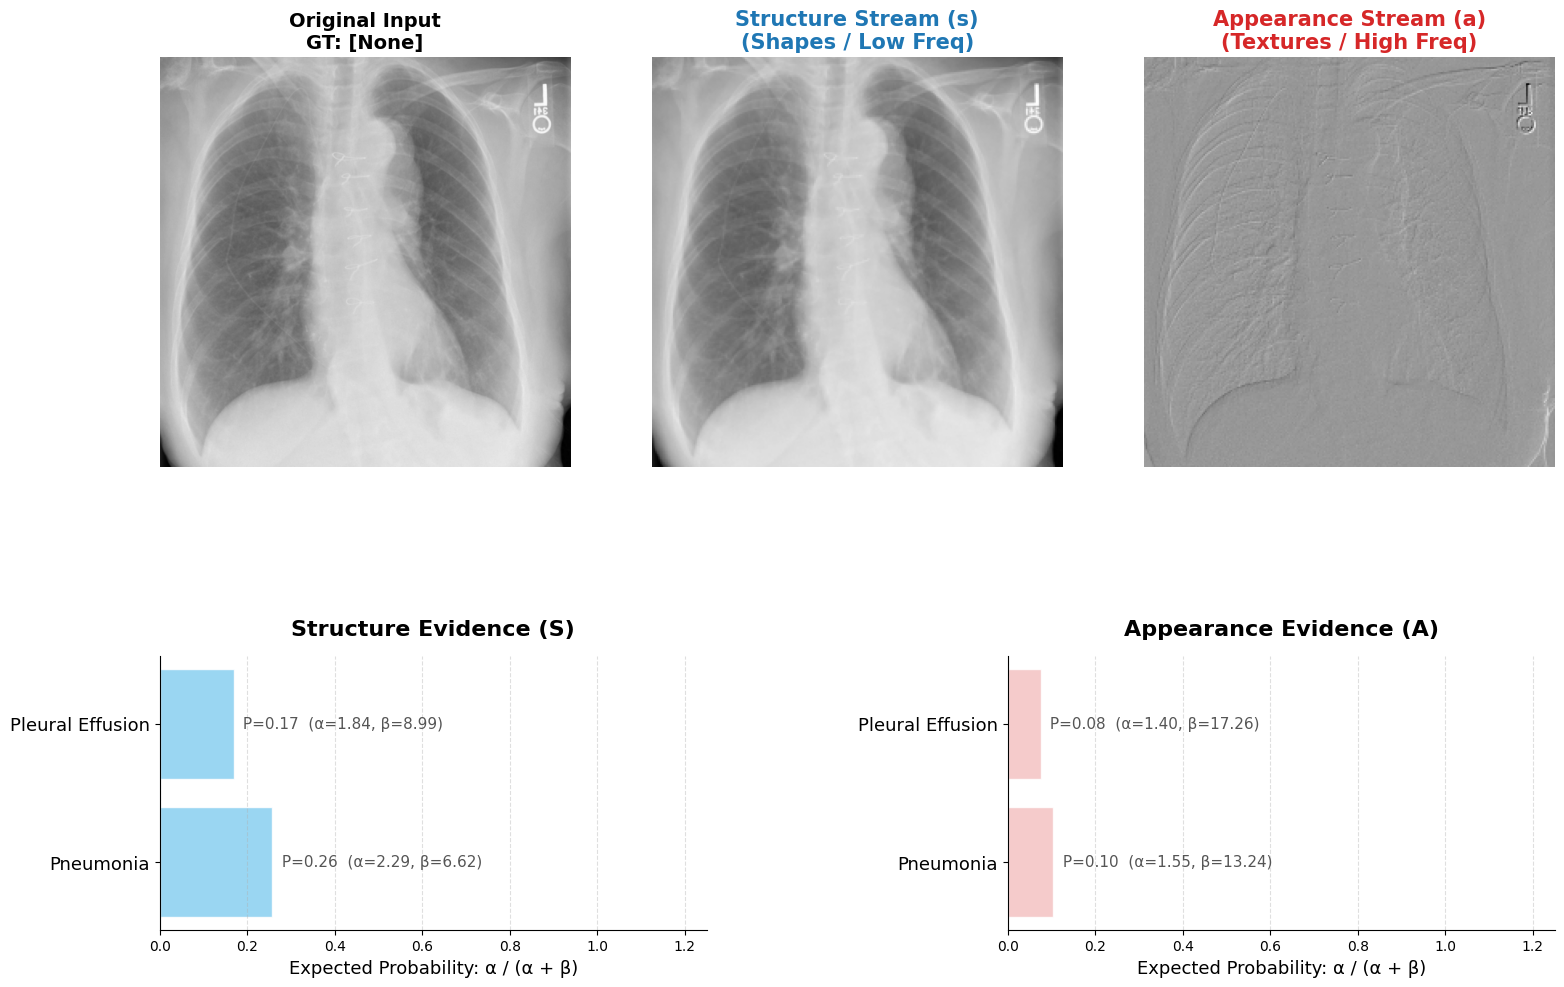

In [6]:
wavename = 'haar'
dwt2D = DWT_2D(wavename).to(DEVICE)
visualize_evidence_explainability(models_dict, dwt2D, common_val_loader, LABEL_COLUMNS, DEVICE, sample_idx=1, batch_id=1)

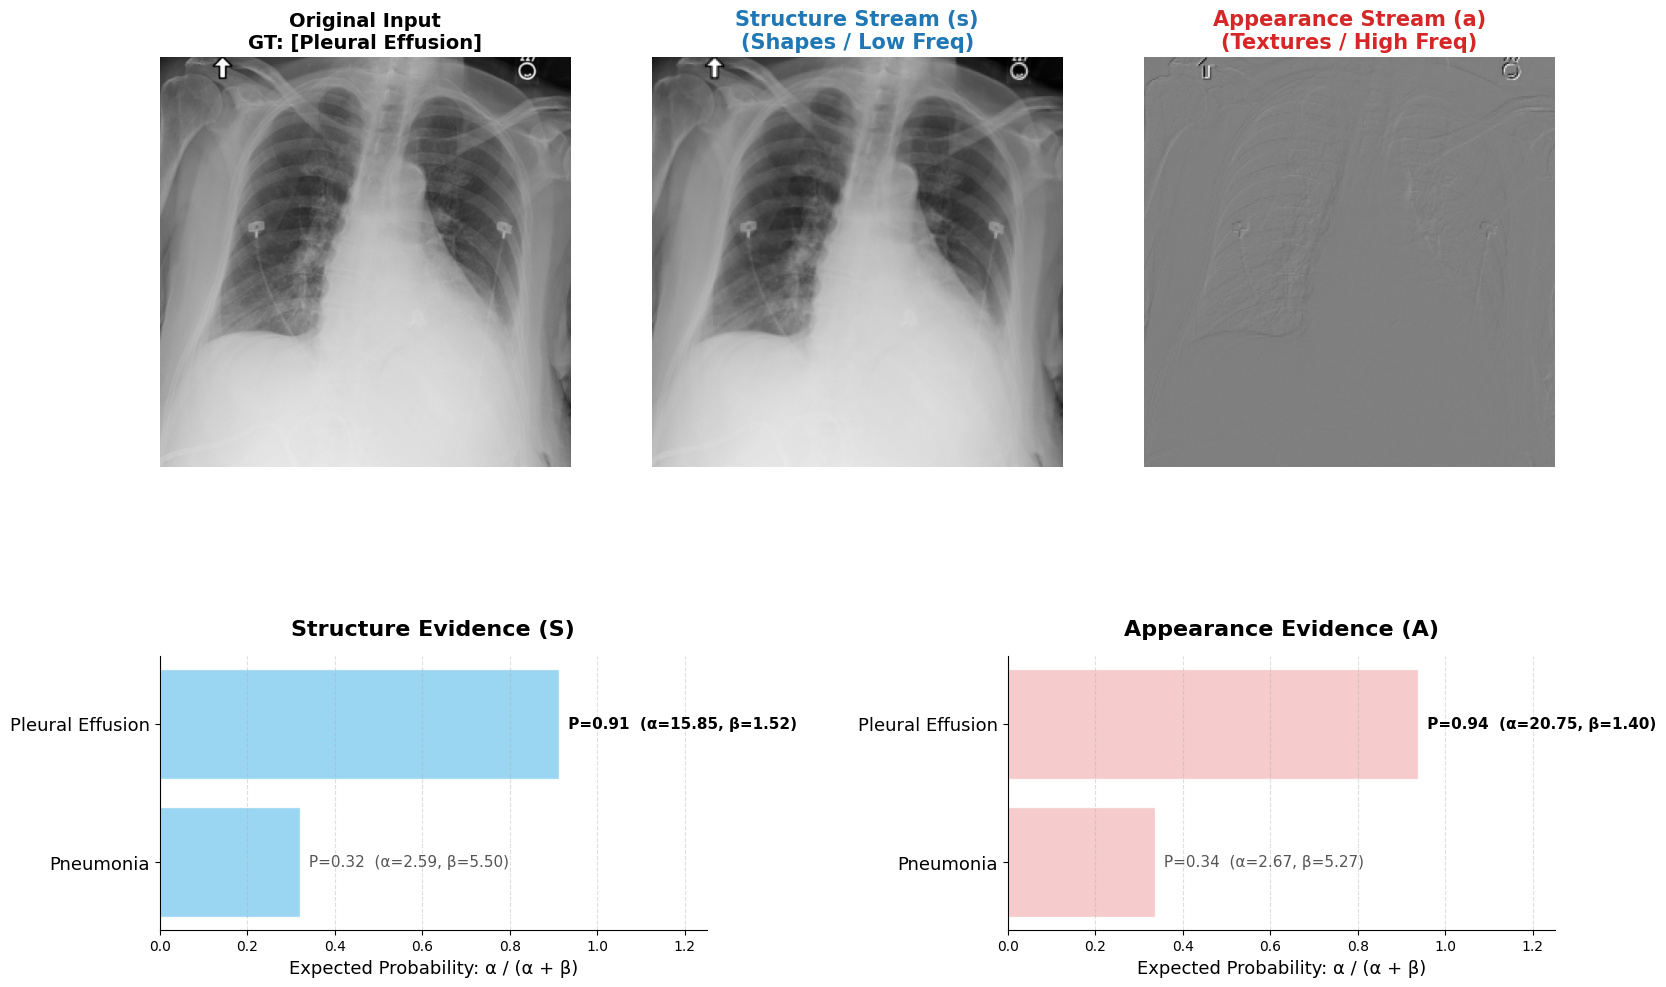

In [7]:
wavename = 'haar'
dwt2D = DWT_2D(wavename).to(DEVICE)
visualize_evidence_explainability(models_dict, dwt2D, common_val_loader, LABEL_COLUMNS, DEVICE, sample_idx=2, batch_id=1)

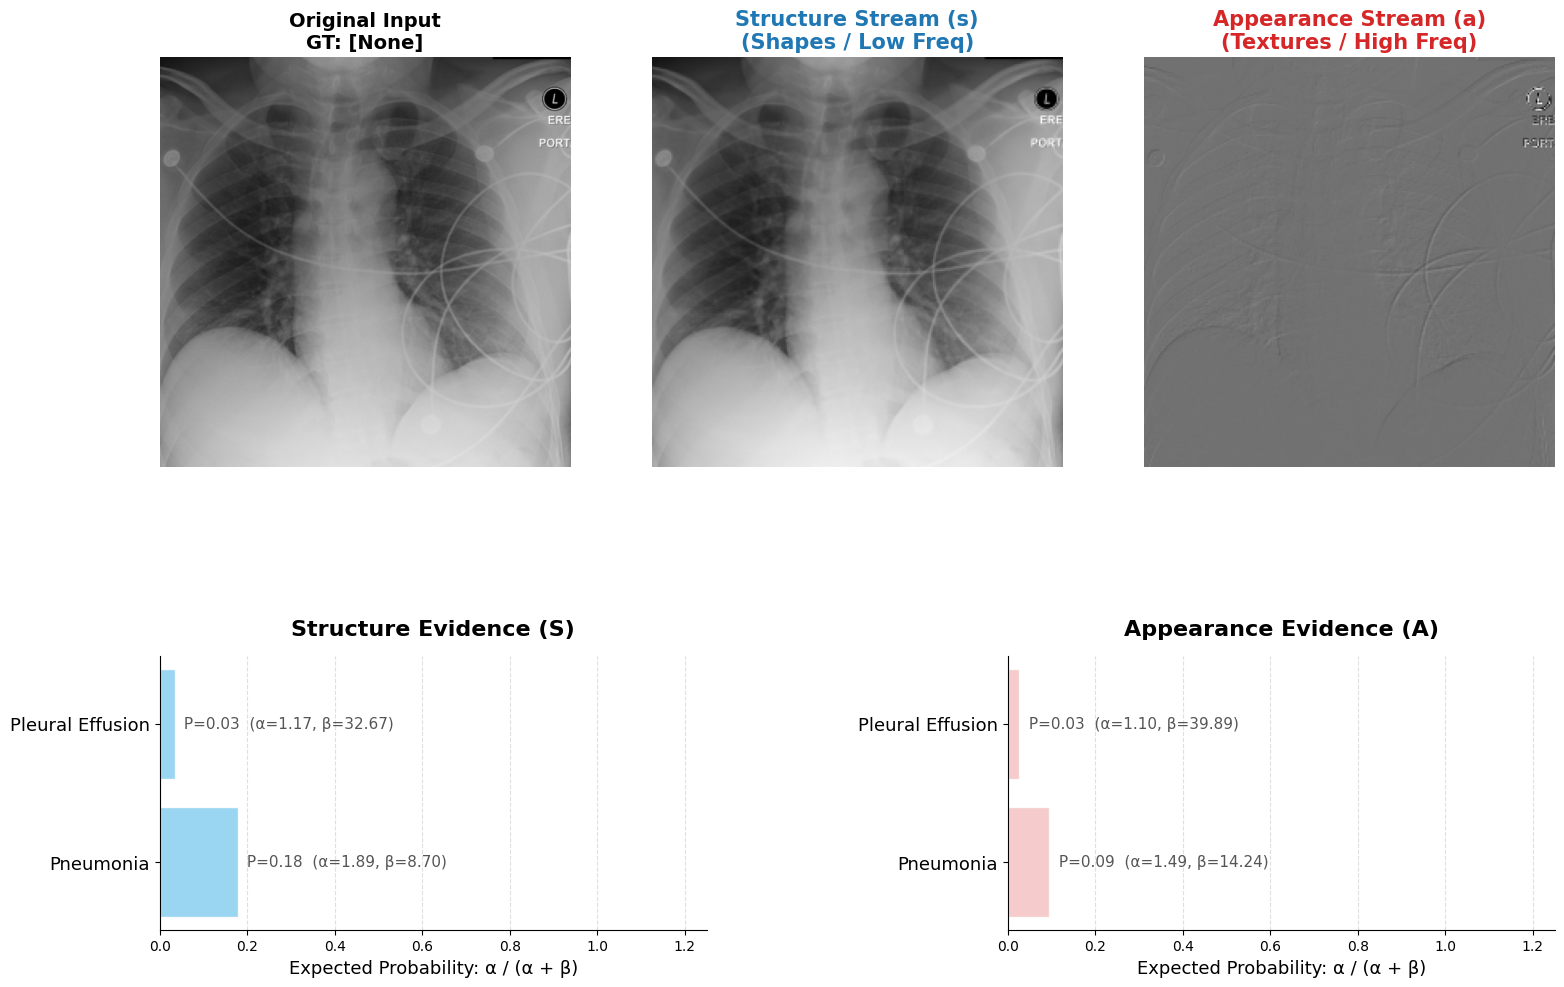

In [8]:
wavename = 'haar'
dwt2D = DWT_2D(wavename).to(DEVICE)
visualize_evidence_explainability(models_dict, dwt2D, common_val_loader, LABEL_COLUMNS, DEVICE, sample_idx=3, batch_id=1)

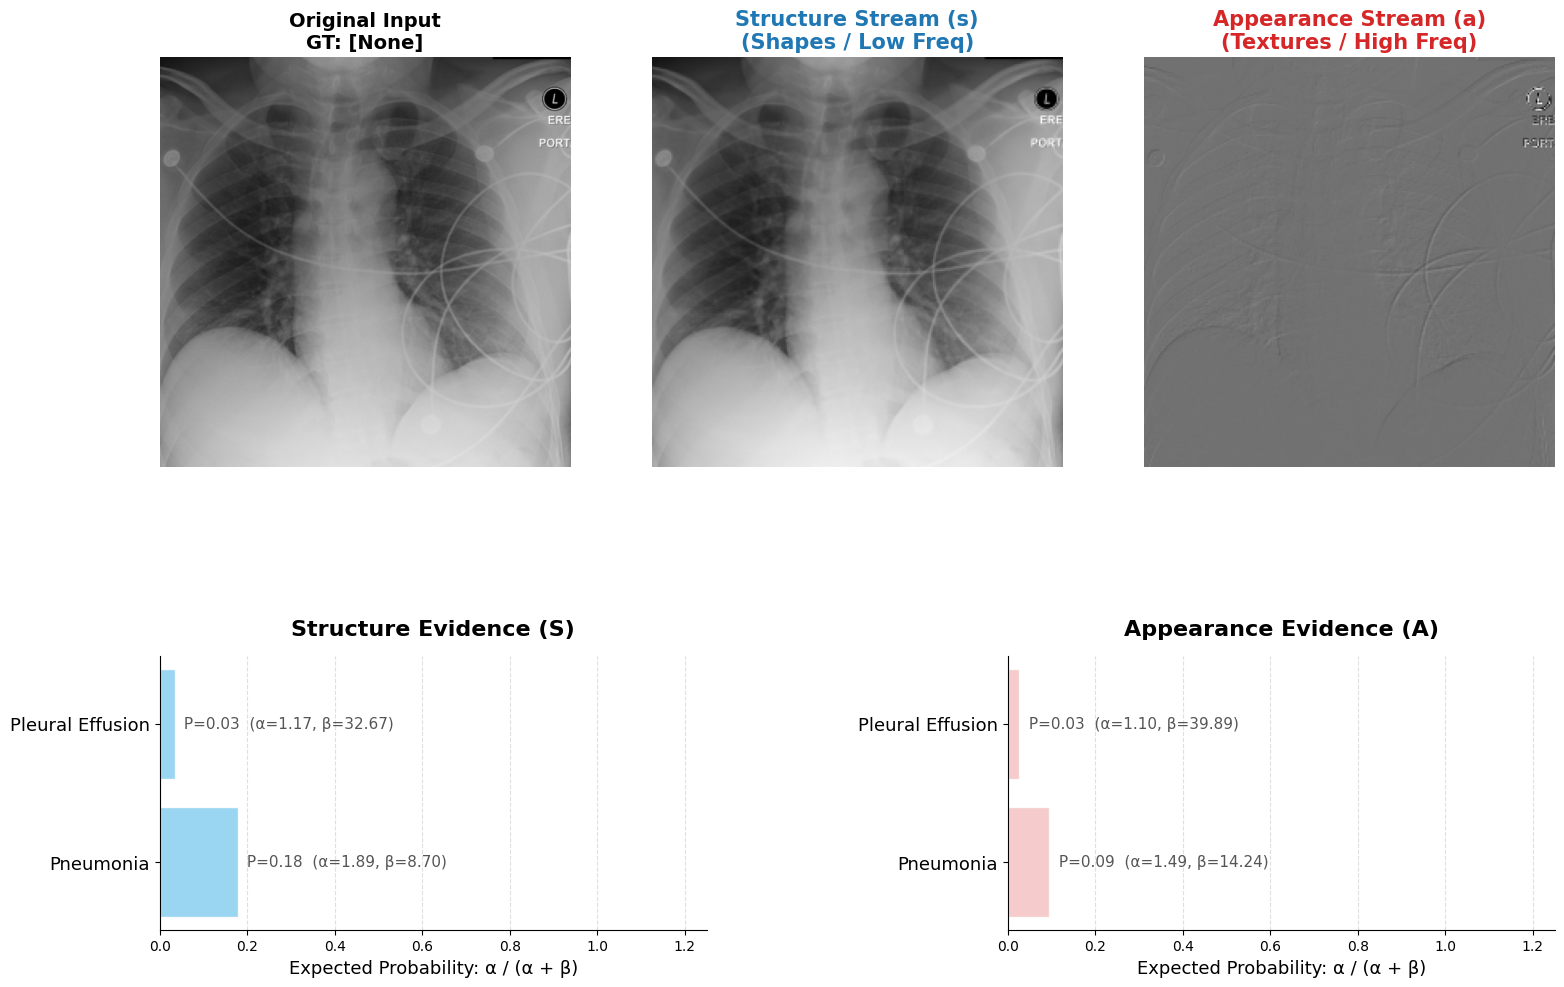

In [9]:
wavename = 'haar'
dwt2D = DWT_2D(wavename).to(DEVICE)
visualize_evidence_explainability(models_dict, dwt2D, common_val_loader, LABEL_COLUMNS, DEVICE, sample_idx=4, batch_id=1)

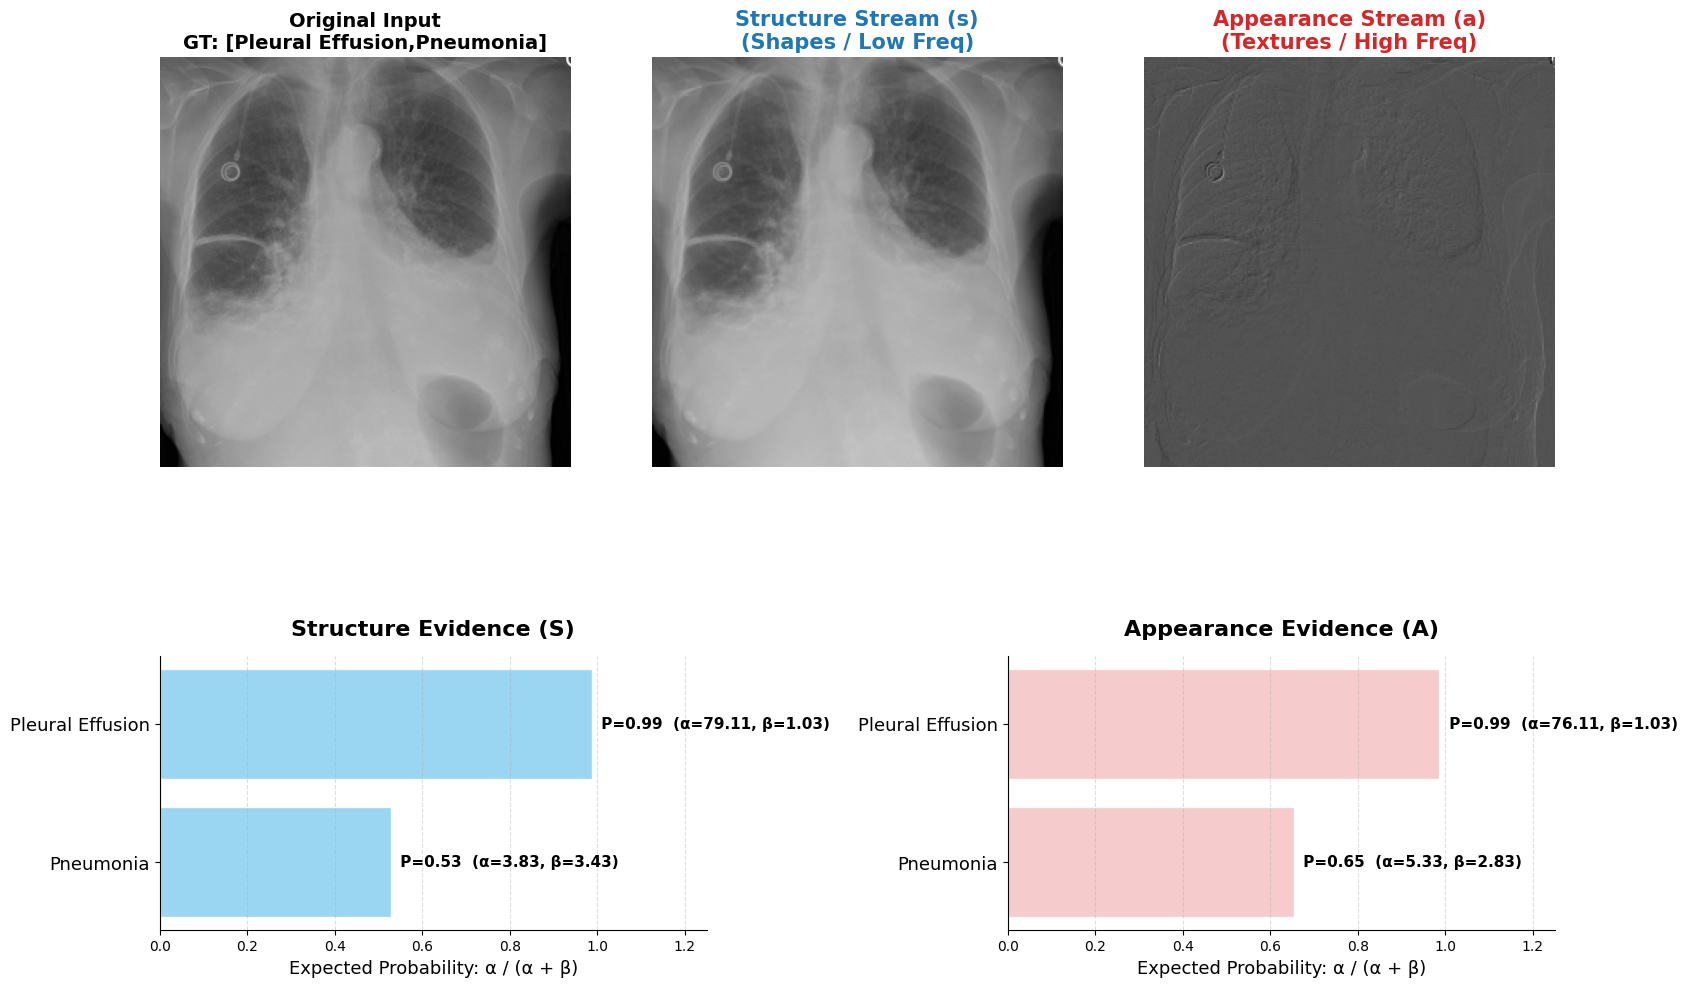

In [10]:
wavename = 'haar'
dwt2D = DWT_2D(wavename).to(DEVICE)
visualize_evidence_explainability(models_dict, dwt2D, common_val_loader, LABEL_COLUMNS, DEVICE, sample_idx=5, batch_id=1)

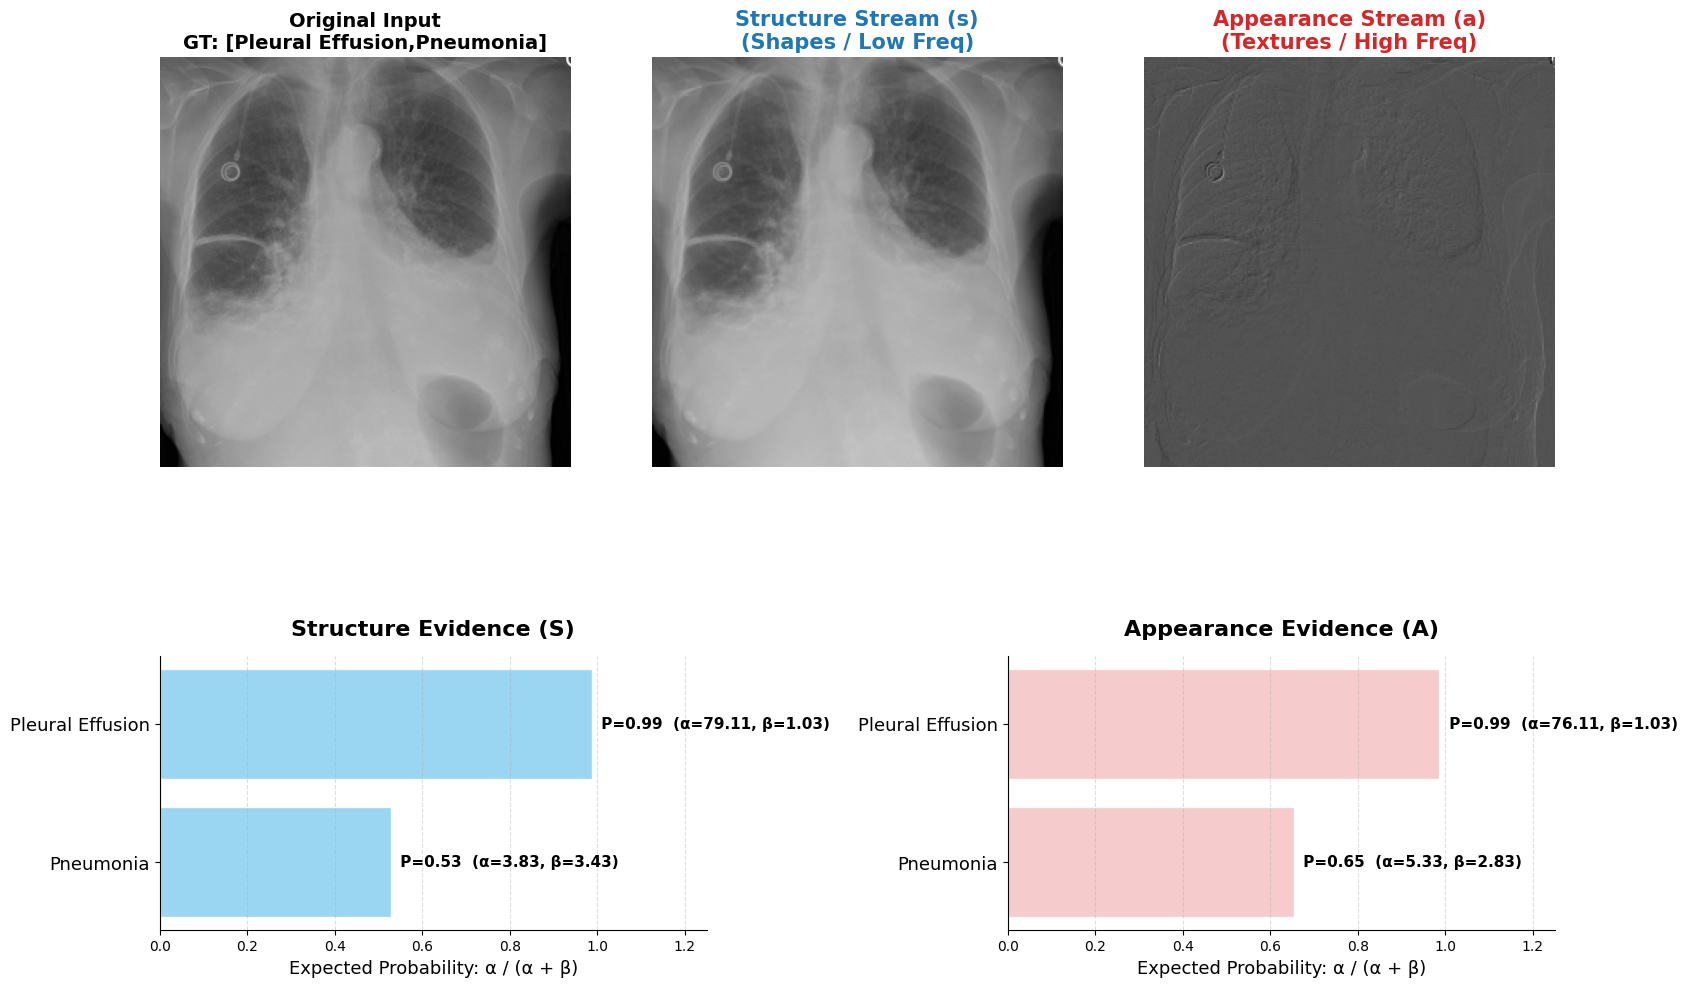

In [11]:
wavename = 'haar'
dwt2D = DWT_2D(wavename).to(DEVICE)
visualize_evidence_explainability(models_dict, dwt2D, common_val_loader, LABEL_COLUMNS, DEVICE, sample_idx=6, batch_id=1)

In [ ]:
wavename = 'haar'
dwt2D = DWT_2D(wavename).to(DEVICE)
visualize_evidence_explainability(models_dict, dwt2D, common_val_loader, LABEL_COLUMNS, DEVICE, sample_idx=7, batch_id=1)